[![Abrir en Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/andres22feli/SI_7011_PROYECTO_INTEGRADOR_Andres_Agudelo/blob/main/notebooks/proyecto_completo.ipynb)

# Estimación de PAS/PAD desde PPG y ECG (MIMIC-BP) — SI7011

Notebook único: corre todo el flujo del proyecto **por partes** (cada parte puede ejecutarse por separado, en orden).

| Parte | Contenido |
|---|---|
| 0 | Configuración (Colab o local) |
| 1 | Contrato de datos, partición por paciente y caché preprocesado |
| 2 | Línea base y chequeos previos |
| 3 | Experimentos MLP |
| 4 | Experimentos GRU con patching |
| 5 | TimesFM 2.5 (probe lineal y LoRA) |
| 6 | Selección por validación, test, tabla 3×3 y `predict_raw` |
| 7 | Guardar resultados en Drive (solo Colab) |

**En Colab:** *Entorno de ejecución → Cambiar tipo de entorno → GPU (T4)*. Los datos y el caché se leen de
`Mi unidad/dl_bp/{data,cache}` en Google Drive.


## Parte 0 · Configuración

In [14]:
# Parte 0 · Configuración. En Colab: instala dependencias, clona el repo, monta Drive y enlaza data/ y cache/.
import os, sys, subprocess
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
REPO_URL = "https://github.com/andres22feli/SI_7011_PROYECTO_INTEGRADOR_Andres_Agudelo.git"
PROJECT = Path("/content/proyecto")
DRIVE_DIR = Path("/content/drive/MyDrive/dl_bp")      # contiene data/ y cache/

if IN_COLAB:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "mlflow==3.18.0", "transformers==5.22.1",
                    "peft==0.21.2", "accelerate==1.15.0", "huggingface_hub==2.4.0", "tabulate"], check=True)
    if (PROJECT / ".git").exists():
        subprocess.run(["git", "-C", str(PROJECT), "pull", "--ff-only"], check=True)
    else:
        subprocess.run(["git", "clone", REPO_URL, str(PROJECT)], check=True)

    from google.colab import drive
    drive.mount("/content/drive")
    for carpeta in ("data", "cache"):
        origen, enlace = DRIVE_DIR / carpeta, PROJECT / carpeta
        if not origen.exists():
            raise FileNotFoundError(f"Falta {origen}: sube data/ y cache/ a Mi unidad/dl_bp/")
        if enlace.is_symlink() or enlace.exists():
            enlace.unlink() if enlace.is_symlink() else subprocess.run(["rm", "-rf", str(enlace)], check=True)
        enlace.symlink_to(origen, target_is_directory=True)
    os.chdir(PROJECT)   # el proyecto busca su raíz subiendo desde el cwd


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [15]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [16]:
import sys, json, time, warnings
from pathlib import Path
warnings.filterwarnings("ignore")
ROOT = Path.cwd().resolve()
while not (ROOT / "src" / "bp").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))
import numpy as np, torch
print("ROOT:", ROOT, "| cuda:", torch.cuda.is_available())


ROOT: /content/proyecto | cuda: True


# Parte 1 · Contrato de datos, partición por paciente y caché preprocesado

Flujo (SI7011): contrato → duplicados → partición **por paciente** → acondicionamiento → estadísticas de etiquetas **solo con train**.
Entradas permitidas: PPG y ECG. ABP produce las etiquetas, así que nunca se usa como entrada.

In [17]:
from bp.contract import (read_subject_ids, check_patient, duplicate_report, build_data_card, save_data_card,
                         MIN_VALID_SEGMENTS)
from bp.paths import DATA, DATA_CARD, SPLIT_JSON, PREPROCESSED, ARTIFACTS

ids = read_subject_ids()
print("IDs en subject_ids.txt:", len(ids))
present = {m: {p.name.split('_')[0] for p in (DATA / m).glob('*.npy')} for m in ('ppg', 'ecg', 'labels')}
for m, s in present.items():
    assert set(ids) == s, f"{m}: los archivos no coinciden con subject_ids.txt"
print("ppg / ecg / labels cubren exactamente los mismos pacientes")

IDs en subject_ids.txt: 1524
ppg / ecg / labels cubren exactamente los mismos pacientes


## 1. Contrato por paciente
Política: un segmento inválido se descarta; el paciente se excluye si es ilegible o le quedan menos de 15 segmentos válidos.

In [18]:
import pickle
from pathlib import Path
from joblib import Parallel, delayed
from tqdm.notebook import tqdm

t0 = time.time()
cache_file = Path("cache/reports_cache.pkl")

if cache_file.exists():
    print("Cargando reportes desde el caché...")
    with open(cache_file, "rb") as f:
        reports = pickle.load(f)
else:
    print("Procesando pacientes en paralelo (primera vez)...")
    reports = Parallel(n_jobs=-1)(
        delayed(check_patient)(s) for s in tqdm(ids, desc="Procesando pacientes")
    )
    cache_file.parent.mkdir(parents=True, exist_ok=True)
    with open(cache_file, "wb") as f:
        pickle.dump(reports, f)

masks = {r['subject_id']: r['valid_mask'] for r in reports}
excluded = [{"subject_id": r['subject_id'], "reason": "; ".join(r['issues']) or f"{r['n_valid']} segmentos válidos"}
            for r in reports if r['issues'] or r['n_valid'] < MIN_VALID_SEGMENTS]
kept = [s for s in ids if s not in {e['subject_id'] for e in excluded}]
n_valid = sum(int(masks[s].sum()) for s in kept)
print(f"{time.time()-t0:.0f}s | pacientes conservados {len(kept)}/{len(ids)} | excluidos {len(excluded)} | "
      f"segmentos válidos {n_valid} | segmentos descartados {sum(int((~masks[s]).sum()) for s in kept)}")

Cargando reportes desde el caché...
1s | pacientes conservados 1524/1524 | excluidos 0 | segmentos válidos 45720 | segmentos descartados 0


## 2. Duplicados (antes de partir)
SHA-1 sobre cada segmento (PPG+ECG) para detectar réplicas entre pacientes.

In [19]:
dup = duplicate_report(kept, mask_by_id=masks)
print(dup)
# Política: se descarta la réplica (el primer paciente conserva el segmento) y se recalcula todo antes de partir.
for sid, segs in dup['drop_segments'].items():
    masks[sid] = masks[sid].copy(); masks[sid][segs] = False
dup_after = duplicate_report(kept, mask_by_id=masks)
assert dup_after['n_segments_dropped'] == 0, dup_after
kept = [s for s in kept if masks[s].sum() >= MIN_VALID_SEGMENTS]
print("pacientes:", len(kept), "| segmentos válidos tras quitar duplicados:", sum(int(masks[s].sum()) for s in kept))

{'drop_segments': {'p042858': [14, 17, 25, 26, 28], 'p062561': [4, 22, 23, 24, 27, 29], 'p083120': [3], 'p085508': [13, 15, 17, 18, 20, 22, 25, 26, 29], 'p090269': [17, 18, 20, 21, 22, 24, 26, 27, 29]}, 'n_segments_dropped': 30, 'cross_patient_duplicates': {'p083120': ['p072885']}, 'n_patients_with_cross_duplicates': 1}
pacientes: 1524 | segmentos válidos tras quitar duplicados: 45690


## 3. Partición 60/20/20 por paciente (seed=0)

In [22]:
from bp.split import make_split, save_split, assert_no_leak
split = make_split(kept, seed=0)
assert_no_leak(split)
assert len(set(split['train']) & set(split['test'])) == 0
save_split(split)
for k, v in split.items():
    print(k, len(v), "pacientes", sum(int(masks[s].sum()) for s in v), "segmentos")

train 914 pacientes 27396 segmentos
val 305 pacientes 9149 segmentos
test 305 pacientes 9145 segmentos


## 4. Acondicionamiento: Butterworth pasa-banda de fase cero + z-score por segmento
Se preprocesa una sola vez, en float64, y se guarda en float32.

In [24]:
from bp.preprocess import build_cache, preprocess_signal
from tqdm.notebook import tqdm
import time

print("Iniciando el proceso de acondicionamiento y construcción del caché...")
t0 = time.time()

# Ejecutamos la construcción del caché
info = build_cache(kept, masks)
print("\nInformación del caché:", info, f"| Tiempo total: {time.time()-t0:.0f}s")

print("\nArchivos generados en el directorio preprocesado:")
for f in sorted(PREPROCESSED.glob('*.npy')):
    print(f"{f.name}: {f.stat().st_size/1e6:.1f} MB")

Iniciando el proceso de acondicionamiento y construcción del caché...

Información del caché: {'n_segments': 45690, 'n_subjects': 1524} | Tiempo total: 46s

Archivos generados en el directorio preprocesado:
ecg.npy: 685.4 MB
labels.npy: 0.4 MB
ppg.npy: 685.4 MB
timesfm_emb_ecg.npy: 233.9 MB
timesfm_emb_ppg.npy: 233.9 MB


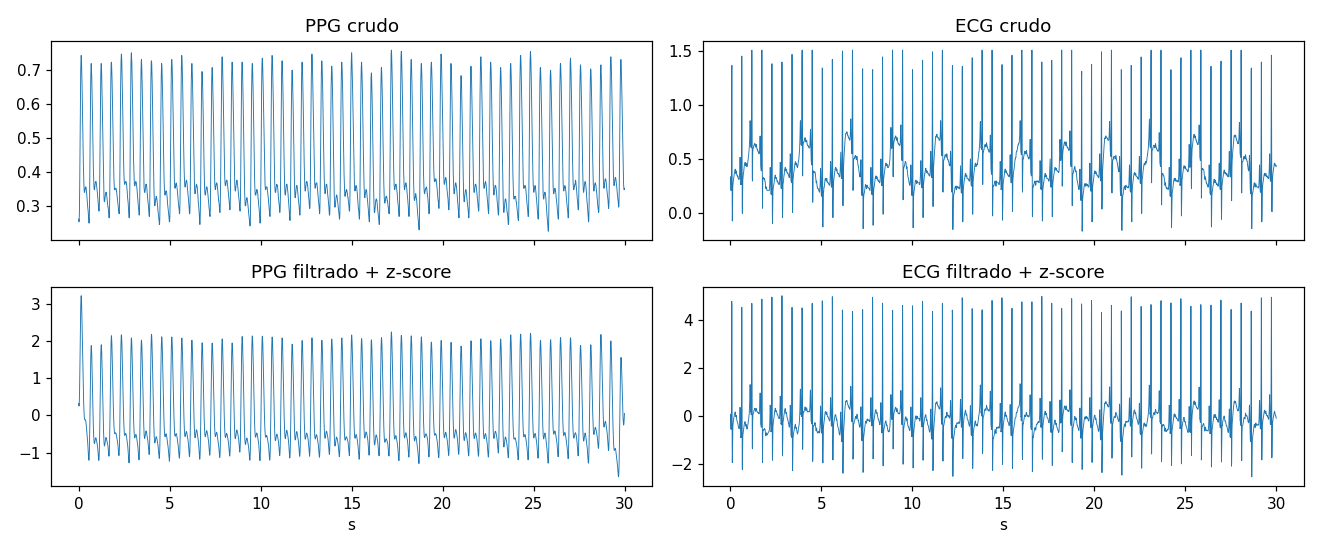

media/std del segmento filtrado: 0.0 1.0


In [29]:
import matplotlib.pyplot as plt
from IPython.display import display, Image
import numpy as np

sid = split['train'][3]
raw_p = np.load(DATA/'ppg'/f'{sid}_ppg.npy')[0]; raw_e = np.load(DATA/'ecg'/f'{sid}_ecg.npy')[0]
fp = preprocess_signal(raw_p, 'ppg')[0]; fe = preprocess_signal(raw_e, 'ecg')[0]
t = np.arange(3750)/125

fig, ax = plt.subplots(2, 2, figsize=(12, 5), sharex='col')
for j, (raw, f, n) in enumerate([(raw_p, fp, 'PPG'), (raw_e, fe, 'ECG')]):
    ax[0, j].plot(t, raw, lw=.6); ax[0, j].set_title(f'{n} crudo')
    ax[1, j].plot(t, f, lw=.6); ax[1, j].set_title(f'{n} filtrado + z-score')
    ax[1, j].set_xlabel('s')

plt.tight_layout()
graph_path = ARTIFACTS/'fig_preprocesamiento.png'
plt.savefig(graph_path, dpi=110)
plt.close(fig)  # Liberar memoria de la figura cerrada

# Mostrar la gráfica en Colab
display(Image(filename=str(graph_path)))
print("media/std del segmento filtrado:", fp.mean().round(4), fp.std().round(4))

## 5. Etiquetas: estadísticas de normalización **solo con train**

In [30]:
from bp.split import load_split
from bp.dataset import split_rows, label_stats
from bp.experiment import save_label_stats
labels = np.load(PREPROCESSED/'labels.npy')
tr_rows, _ = split_rows(load_split()['train'])
y_mean, y_std = label_stats(labels[tr_rows])
save_label_stats(y_mean, y_std)
print("train  PAS/PAD media", y_mean.round(2), "DE", y_std.round(2))
for k in ('val', 'test'):
    r, _ = split_rows(load_split()[k]); print(k, "media", labels[r].mean(0).round(2), "DE", labels[r].std(0).round(2))

train  PAS/PAD media [112.78  58.48] DE [18.14 12.51]
val media [112.83  58.78] DE [17.46 12.07]
test media [112.92  58.01] DE [17.28 11.66]


## 6. data_card.json

In [31]:
card = build_data_card(ids, kept, masks, excluded, dup, labels)
card['split'] = {k: {'n_subjects': len(v), 'n_segments': sum(int(masks[s].sum()) for s in v)} for k, v in split.items()}
card['split_seed'] = 0
card['preprocessing'] = {'filters': {'order': 4, 'ppg_band_hz': [0.5, 8.0], 'ecg_band_hz': [0.5, 40.0], 'zero_phase': True, 'fs': 125},
                         'input_norm': 'z-score por segmento (por instancia)', 'label_norm': 'z-score con media/DE de train'}
save_data_card(card)
print(json.dumps({k: card[k] for k in ('n_subjects_kept','n_segments_valid','split','label_descriptives_mmHg')}, indent=1))

{
 "n_subjects_kept": 1524,
 "n_segments_valid": 45690,
 "split": {
  "train": {
   "n_subjects": 914,
   "n_segments": 27396
  },
  "val": {
   "n_subjects": 305,
   "n_segments": 9149
  },
  "test": {
   "n_subjects": 305,
   "n_segments": 9145
  }
 },
 "label_descriptives_mmHg": {
  "pas": {
   "mean": 112.81552124023438,
   "std": 17.83379364013672,
   "min": 63.79999923706055,
   "max": 185.8000030517578,
   "p5": 85.9000015258789,
   "p95": 143.8000030517578
  },
  "pad": {
   "mean": 58.44516372680664,
   "std": 12.258400917053223,
   "min": 31.100000381469727,
   "max": 115.5999984741211,
   "p5": 40.79999923706055,
   "p95": 80.69999694824219
  }
 }
}


# Parte 2 · Experimentos MLP

Tres corridas (PPG, ECG, PPG+ECG) con **el mismo presupuesto**: AdamW(lr=1e-3, wd=1e-2), warmup de 1 época + coseno por lote,
batch 128, hasta 30 épocas, early stopping (paciencia 5) sobre `val_loss`, `clip_grad_norm_(1.0)`, semilla 0 antes de construir cada modelo.
Se registra en MLflow (`mlflow.db`). Arquitectura: `Linear(bias=False) → BatchNorm1d → ReLU → [Dropout]` ×3 (512→256→128) → `Linear(128, 2)`; He en capas ocultas y la última capa en 0. La variante base no usa Dropout; como sobreajusta en las primeras épocas (la `train_loss` baja y la `val_loss` sube) se añade la variante con `Dropout(0.2)` del plan y se elige por validación.
**Solo train y val**; test se evalúa una vez en la Parte 6.

In [ ]:
from bp.experiment import get_data, load_label_stats, save_val_result
from bp.train import fit
from bp.dataset import INPUT_SETS
import matplotlib; matplotlib.use("Agg")
import matplotlib.pyplot as plt
y_mean, y_std = load_label_stats()
runs = {}

In [ ]:
variants = [('', {}), ('_do0.2', {'dropout': 0.2})]   # (sufijo, hiperparámetros del modelo); se elige por val_loss en la Parte 6
for suffix, model_kw in variants:
    for name, inputs in INPUT_SETS.items():
        tr, va = get_data('train', inputs), get_data('val', inputs)
        res = fit('build_mlp', inputs, tr, va, y_mean, y_std, run_name='mlp' + suffix + '_' + name, model_kw=model_kw)
        save_val_result(res); runs[suffix + name] = res
        print(f"==> mlp{suffix} {name}: mejor época {res['best_epoch']} val_loss {res['best_val_loss']:.4f} "
              f"MAE val PAS/PAD {res['val_mae_pas']:.2f}/{res['val_mae_pad']:.2f} mmHg ({res['seconds']:.0f}s)")
        del tr, va; torch.cuda.empty_cache()

2026/11/07 00:54:01 INFO mlflow.store.db.utils: Creating initial MLflow database tables...
2026/11/07 00:54:01 INFO mlflow.store.db.utils: Updating database tables
2026/11/07 00:54:03 INFO mlflow.tracking.fluent: Experiment with name 'mimic_bp' does not exist. Creating a new experiment.


[mlp_ppg] ep 00 train 0.9858 val 0.9161 MAE 14.13/9.24 gn 1.06 t 1s
[mlp_ppg] ep 01 train 0.9676 val 0.9091 MAE 14.13/9.22 gn 1.02 t 2s
[mlp_ppg] ep 02 train 0.9504 val 0.9048 MAE 14.12/9.21 gn 0.97 t 3s
[mlp_ppg] ep 03 train 0.9358 val 0.9086 MAE 14.09/9.15 gn 0.88 t 4s
[mlp_ppg] ep 04 train 0.9182 val 0.9149 MAE 14.08/9.23 gn 0.84 t 5s
[mlp_ppg] ep 05 train 0.9016 val 0.9219 MAE 14.10/9.20 gn 0.85 t 6s
[mlp_ppg] ep 06 train 0.8805 val 0.9156 MAE 14.08/9.26 gn 0.78 t 7s
[mlp_ppg] ep 07 train 0.8596 val 0.9296 MAE 14.24/9.26 gn 0.78 t 8s
==> mlp ppg: mejor época 2 val_loss 0.9048 MAE val PAS/PAD 14.12/9.21 mmHg (8s)
[mlp_ecg] ep 00 train 0.9951 val 0.9436 MAE 14.18/9.51 gn 1.05 t 1s
[mlp_ecg] ep 01 train 0.9315 val 0.9552 MAE 14.31/9.58 gn 1.16 t 2s
[mlp_ecg] ep 02 train 0.7003 val 1.0567 MAE 15.04/10.19 gn 1.34 t 3s
[mlp_ecg] ep 03 train 0.4269 val 1.1713 MAE 15.76/10.55 gn 1.17 t 3s
[mlp_ecg] ep 04 train 0.2587 val 1.2003 MAE 15.86/10.66 gn 0.98 t 4s
[mlp_ecg] ep 05 train 0.1696 val 

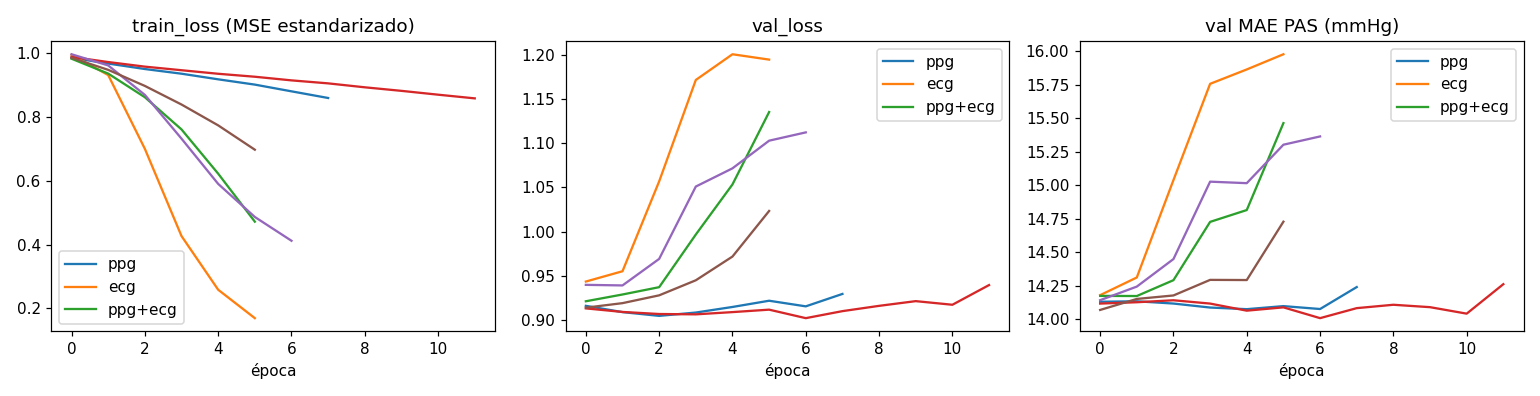

,entrada,mejor_epoca,val_loss,MAE_PAS,MAE_PAD
0,ppg,2,0.904814,14.118120,9.210252
1,ecg,0,0.943586,14.180633,9.508372
2,ppg+ecg,0,0.921317,14.175214,9.299614
3,_do0.2ppg,6,0.902244,14.009278,9.195817
4,_do0.2ecg,1,0.939204,14.244372,9.568873
5,_do0.2ppg+ecg,0,0.914093,14.070423,9.295163


In [ ]:
fig, ax = plt.subplots(1, 3, figsize=(14, 3.6))
for name, res in runs.items():
    h = res['history']
    ax[0].plot([r['train_loss'] for r in h], label=name); ax[1].plot([r['val_loss'] for r in h], label=name)
    ax[2].plot([r['val_mae_pas_mmHg'] for r in h], label=name)
for a, t in zip(ax, ['train_loss (MSE estandarizado)', 'val_loss', 'val MAE PAS (mmHg)']):
    a.set_title(t); a.set_xlabel('época'); a.legend()
plt.tight_layout()

# Guardar la gráfica
graph_path = ROOT / 'artifacts' / 'fig_curvas_mlp.png'
plt.savefig(graph_path, dpi=110)
plt.close(fig) # Liberar memoria de la figura cerrada

# Mostrar la gráfica en Colab
from IPython.display import display, Image
display(Image(filename=graph_path))

import pandas as pd
pd.DataFrame([{'entrada': k, 'mejor_epoca': r['best_epoch'], 'val_loss': r['best_val_loss'], 'MAE_PAS': r['val_mae_pas'], 'MAE_PAD': r['val_mae_pad']}
              for k, r in runs.items()])

# Parte 4 · Experimentos GRU con patching

Tres corridas (PPG, ECG, PPG+ECG) con **el mismo presupuesto**: AdamW(lr=1e-3, wd=1e-2), warmup de 1 época + coseno por lote,
batch 128, hasta 30 épocas, early stopping (paciencia 5) sobre `val_loss`, `clip_grad_norm_(1.0)`, semilla 0 antes de construir cada modelo.
Se registra en MLflow (`mlflow.db`). Arquitectura: ventanas de 25 muestras (T=150) → `GRU(64, 2 capas)` → `Linear(64, 2)` sobre el último estado oculto.
**Solo train y val**; test se evalúa una vez en la Parte 6.

In [ ]:
from bp.experiment import get_data, load_label_stats, save_val_result
from bp.train import fit
from bp.dataset import INPUT_SETS
import matplotlib; matplotlib.use("Agg")
import matplotlib.pyplot as plt
y_mean, y_std = load_label_stats()
runs = {}

In [ ]:
variants = [('', {})]   # (sufijo, hiperparámetros del modelo); se elige por val_loss en la Parte 6
for suffix, model_kw in variants:
    for name, inputs in INPUT_SETS.items():
        tr, va = get_data('train', inputs), get_data('val', inputs)
        res = fit('build_gru', inputs, tr, va, y_mean, y_std, run_name='gru' + suffix + '_' + name, model_kw=model_kw)
        save_val_result(res); runs[suffix + name] = res
        print(f"==> gru{suffix} {name}: mejor época {res['best_epoch']} val_loss {res['best_val_loss']:.4f} "
              f"MAE val PAS/PAD {res['val_mae_pas']:.2f}/{res['val_mae_pad']:.2f} mmHg ({res['seconds']:.0f}s)")
        del tr, va; torch.cuda.empty_cache()

In [ ]:
fig, ax = plt.subplots(1, 3, figsize=(14, 3.6))
for name, res in runs.items():
    h = res['history']
    ax[0].plot([r['train_loss'] for r in h], label=name); ax[1].plot([r['val_loss'] for r in h], label=name)
    ax[2].plot([r['val_mae_pas_mmHg'] for r in h], label=name)
for a, t in zip(ax, ['train_loss (MSE estandarizado)', 'val_loss', 'val MAE PAS (mmHg)']):
    a.set_title(t); a.set_xlabel('época'); a.legend()
plt.tight_layout(); plt.savefig(ROOT / 'artifacts' / 'fig_curvas_gru.png', dpi=110)
import pandas as pd
pd.DataFrame([{'entrada': k, 'mejor_epoca': r['best_epoch'], 'val_loss': r['best_val_loss'], 'MAE_PAS': r['val_mae_pas'], 'MAE_PAD': r['val_mae_pad']}
              for k, r in runs.items()])

# Parte 5 · TimesFM 2.5 (probe lineal y LoRA) sobre las tres entradas

Checkpoint `google/timesfm-2.5-200m-transformers` (200 M, contexto máx. 16 384, parche de 32). Una señal de 3 750 muestras cabe sin recortar:
se rellena por la izquierda con 26 ceros enmascarados hasta 3 776 = 118 parches. Cada canal pasa por el backbone; se promedian los estados ocultos
sobre los parches (1 280-d) y, con 2 canales, se concatenan antes de `Linear(C·1280, 2)`.

**Paso 1 – probe lineal:** backbone congelado; los embeddings se calculan una sola vez y se guardan en caché.
**Paso 2 – LoRA:** adaptadores r=8, α=16 en `q/k/v/o_proj` de las 20 capas; la cabeza arranca desde la del probe.

**Desviaciones del presupuesto (por costo, medido en esta GPU de 8 GB):** un paso de LoRA con 1 canal cuesta ≈ 22 ms/ejemplo, es decir ≈ 10 min por época
(≈ 20 min con 2 canales). Se entrena **3 épocas** (no 30), con bf16 autocast, batch efectivo 128 por acumulación de gradiente (micro-batch 16, u 8 con 2 canales),
y tasa de aprendizaje de los adaptadores **2e-4** en lugar de 2e-5: con B=0 al inicio y solo ≈ 640 pasos, 2e-5 casi no movería los adaptadores
(la guía del curso usa 2e-4–5e-4 para LoRA; 2e-5 es la tasa típica de fine-tuning completo). La cabeza usa 1e-3 como en el plan.

In [ ]:
from bp.experiment import get_data, load_label_stats, save_val_result, device
from bp.train import fit, sanity_checks, DEFAULT_CFG
from bp.dataset import INPUT_SETS
from bp.paths import PREPROCESSED, ARTIFACTS
y_mean, y_std = load_label_stats()
dev = device()
LORA_CFG = {**DEFAULT_CFG, 'lr': 1e-3, 'head_lr': 1e-3, 'backbone_lr': 2e-4, 'epochs': 3, 'patience': 5, 'amp': True, 'eval_batch_size': 32}

## 1. Chequeos previos (TimesFM + LoRA, PPG)
Sobreajuste de 16 ejemplos (64 secuencias no caben con gradientes en 8 GB); MSE inicial sobre 256 ejemplos.

In [ ]:
tr = get_data('train', ['ppg'])
r = sanity_checks('build_timesfm', tr, 1, LORA_CFG, dev, model_kw={'mode': 'lora'}, n_overfit=16, n_init=256, eval_bs=32, amp=True, overfit_steps=200)
print({k: (round(v, 4) if isinstance(v, float) else v) for k, v in r.items() if k != 'grad_zero_layers'}, "| sin gradiente:", r['grad_zero_layers'][:3])
assert 0.8 <= r['init_mse'] <= 1.2 and r['grad_all_finite'] and r['eval_deterministic']
assert r['overfit_loss'] < 0.05, r
(ARTIFACTS / 'sanity_timesfm.json').write_text(json.dumps(r, indent=1))
del tr; torch.cuda.empty_cache()

## 2. Embeddings congelados (una sola pasada por modalidad)

In [ ]:
from bp.models import TimesFMReg
backbone = TimesFMReg(1, mode='probe').to(dev).eval()
for mod in ('ppg', 'ecg'):
    out = PREPROCESSED / f'timesfm_emb_{mod}.npy'
    if out.exists():
        print(mod, 'ya calculado'); continue
    X = np.load(PREPROCESSED / f'{mod}.npy', mmap_mode='r')
    emb = np.empty((len(X), 1280), np.float32)
    t0 = time.time()
    with torch.no_grad(), torch.autocast('cuda', dtype=torch.bfloat16):
        for i in range(0, len(X), 64):
            xb = torch.from_numpy(np.ascontiguousarray(X[i:i + 64])).to(dev)[:, None, :]
            emb[i:i + 64] = backbone.embed(xb).float().cpu().numpy()
    assert np.isfinite(emb).all()
    np.save(out, emb)
    print(mod, emb.shape, f'{time.time() - t0:.0f}s', 'media/std', emb.mean().round(3), emb.std().round(3))
del backbone; torch.cuda.empty_cache()

## 3. Paso 1 — probe lineal sobre embeddings
Mismo presupuesto que MLP/GRU (AdamW 1e-3, wd 1e-2, hasta 30 épocas, paciencia 5); batch 256.

In [ ]:
PROBE_CFG = {**DEFAULT_CFG, 'batch_size': 256}
probes = {}
for name, inputs in INPUT_SETS.items():
    tr, va = get_data('train', inputs, embeddings=True), get_data('val', inputs, embeddings=True)
    res = fit('build_probe_head', inputs, tr, va, y_mean, y_std, cfg=PROBE_CFG, run_name='timesfm_probe_' + name)
    save_val_result(res); probes[name] = res
    print(f"==> probe {name}: val_loss {res['best_val_loss']:.4f} MAE {res['val_mae_pas']:.2f}/{res['val_mae_pad']:.2f}")
    del tr, va; torch.cuda.empty_cache()

## 4. Paso 2 — fine-tuning con LoRA (cabeza inicializada con la del probe)

In [ ]:
lora = {}
for name, inputs in INPUT_SETS.items():
    head = torch.load(probes[name]['checkpoint'], weights_only=False)['state']
    init_head = lambda m, h=head: m.head.load_state_dict({k.split('head.')[1]: v for k, v in h.items()})
    cfg = {**LORA_CFG, 'micro_batch': 16 if len(inputs) == 1 else 8}
    tr, va = get_data('train', inputs), get_data('val', inputs)
    res = fit('build_timesfm', inputs, tr, va, y_mean, y_std, cfg=cfg, run_name='timesfm_lora_' + name,
              model_kw={'mode': 'lora'}, post_build=init_head)
    save_val_result(res); lora[name] = res
    print(f"==> LoRA {name}: mejor época {res['best_epoch']} val_loss {res['best_val_loss']:.4f} MAE {res['val_mae_pas']:.2f}/{res['val_mae_pad']:.2f} ({res['seconds']/60:.0f} min)")
    del tr, va; torch.cuda.empty_cache()

In [ ]:
import pandas as pd
pd.DataFrame([{'entrada': n, 'paso': p, 'mejor_epoca': r['best_epoch'], 'val_loss': r['best_val_loss'], 'MAE_PAS': r['val_mae_pas'], 'MAE_PAD': r['val_mae_pad']}
              for p, d in (('probe', probes), ('LoRA', lora)) for n, r in d.items()])

# Parte 6 · Selección por validación, test una sola vez, tabla 3×3 y `predict_raw`

1. **Selección (solo validación):** para cada (entrada, arquitectura) se elige la corrida con menor `val_loss` (MLP: con y sin Dropout).
2. **Test, una sola vez:** cada modelo elegido se evalúa sobre los 305 pacientes de prueba. La celda se protege con `artifacts/test_results.json`: si existe, se lee en lugar de recalcular.
3. **Métricas:** por paciente (MAE, ME, DE, promediadas sobre pacientes — definición del anteproyecto) y agrupadas sobre todos los segmentos. La DE por paciente descuenta el sesgo de cada paciente; la **comparación con AAMI (ME ≤ 5, DE ≤ 8 mmHg) se hace con las agrupadas**.
**Nota de precisión numérica:** TimesFM se entrenó con autocast bf16, pero la inferencia (evaluación en test y `predict_raw`) se hace en **fp32**: en bf16 el mismo modelo da hasta 0.19 mmHg de diferencia según el tamaño de lote y hasta ≈ 1 mmHg frente a fp32, lo que impide reproducir las predicciones. La primera corrida de esta parte evaluó TimesFM en bf16 (`artifacts/test_results_bf16_primera_corrida.json`); se repitió en fp32 por reproducibilidad, sin cambiar la selección (hecha en validación). MLP y GRU no se ven afectados.
4. **Bundle** del mejor modelo (elegido por validación) y verificación de `predict_raw` contra las predicciones de test.

In [ ]:
import pandas as pd
from bp.experiment import get_data, load_label_stats, load_val_results, device
from bp.train import build_model, load_state, predict_norm
from bp.metrics import per_patient_metrics
from pathlib import Path
from bp.paths import ARTIFACTS, DATA_CARD
y_mean, y_std = load_label_stats()
dev = device()
vals = load_val_results()
print(len(vals), "corridas de validación:", sorted(vals))

## 1. Selección por `val_loss`

In [ ]:
def family(r):
    if r['builder'] == 'build_timesfm': return 'timesfm_lora'
    if r['builder'] == 'build_probe_head': return 'timesfm_probe'
    return r['builder'].replace('build_', '')

best = {}
for name, r in vals.items():
    key = (family(r), '+'.join(r['inputs']))
    if key not in best or r['best_val_loss'] < best[key]['best_val_loss']:
        best[key] = r
# TimesFM es una estrategia de dos pasos (probe -> LoRA): en cada entrada se reporta el paso con menor val_loss
STEP = {'timesfm_lora': 'LoRA', 'timesfm_probe': 'probe'}
chosen = {inp: min(('timesfm_lora', 'timesfm_probe'), key=lambda f: best[(f, inp)]['best_val_loss']) for inp in ('ppg', 'ecg', 'ppg+ecg')}
print('paso de TimesFM elegido por validación:', {i: STEP[f] for i, f in chosen.items()})
sel = pd.DataFrame([{'modelo': k[0], 'entrada': k[1], 'corrida': r['run_name'], 'mejor_epoca': r['best_epoch'],
                     'val_loss': round(r['best_val_loss'], 4), 'val_MAE_PAS': round(r['val_mae_pas'], 2), 'val_MAE_PAD': round(r['val_mae_pad'], 2)}
                    for k, r in sorted(best.items())])
sel

## 2. Evaluación en test (una sola vez)

In [ ]:
TEST_FILE = ARTIFACTS / 'test_results.json'
test_cache = {}   # predicciones por segmento, solo para verificar predict_raw

def load_model(r):
    ck = torch.load(r['checkpoint'], weights_only=False)
    if ck['builder'] == 'build_probe_head':
        m = build_model('build_timesfm', len(ck['inputs']), 0, mode='probe')
    else:
        m = build_model(ck['builder'], len(ck['inputs']), 0, **ck['model_kw'])
    load_state(m, ck['state'])
    return m.to(dev).eval(), ck

def eval_test(r):
    inputs = r['inputs']
    if r['builder'] == 'build_probe_head':      # cabeza sobre embeddings de test precalculados
        te = get_data('test', inputs, embeddings=True)
        ck = torch.load(r['checkpoint'], weights_only=False)
        head = build_model('build_probe_head', te['X'].shape[1], 0).to(dev)
        load_state(head, ck['state'])
        pn = predict_norm(head, te['X'], 4096)
    else:
        te = get_data('test', inputs)
        m, ck = load_model(r)
        pn = predict_norm(m, te['X'], 32 if r['builder'] == 'build_timesfm' else 1024, amp=False)   # inferencia siempre en fp32
        del m
    pred = pn.cpu().numpy() * y_std + y_mean
    return pred, te['y'], te['patient']

if TEST_FILE.exists():
    test_res = json.loads(TEST_FILE.read_text(encoding='utf-8'))
    print("test_results.json ya existe: se lee, NO se vuelve a evaluar test")
else:
    test_res = {}
    # LB-0
    te = get_data('test', ['ppg'], to_device=False)
    test_res['lb0|-'] = per_patient_metrics(np.tile(y_mean, (len(te['y']), 1)), te['y'], te['patient'])
    for (fam, inp), r in sorted(best.items()):
        pred, y, pat = eval_test(r)
        test_res[f'{fam}|{inp}'] = {**per_patient_metrics(pred, y, pat), 'run_name': r['run_name']}
        test_cache[f'{fam}|{inp}'] = pred
        print(f'{fam:14s} {inp:8s}', {k: round(v, 2) for k, v in test_res[f'{fam}|{inp}'].items() if k in ('mae_pas', 'mae_pad')})
        torch.cuda.empty_cache()
    TEST_FILE.write_text(json.dumps(test_res, indent=1), encoding='utf-8')
print(len(test_res), "filas de test")

## 3. Tabla final 3×3 (test, 305 pacientes)
Por paciente: MAE / ME / DE promediados sobre pacientes. Agrupado: ME y DE sobre todos los segmentos (comparables con AAMI).

In [ ]:
NAMES = {'lb0': 'Línea Base (Media)', 'mlp': 'MLP', 'gru': 'GRU', 'timesfm': 'TimesFM 2.5'}
INP = {'ppg': 'PPG', 'ecg': 'ECG', 'ppg+ecg': 'PPG + ECG', '-': '—'}
rows = []
for key, m in test_res.items():
    fam, inp = key.split('|')
    is_tfm = fam.startswith('timesfm')
    rows.append({'Entrada': INP[inp], 'Modelo': NAMES['timesfm' if is_tfm else fam], 'Paso': STEP.get(fam, ''),
                 'seleccionado': (not is_tfm) or chosen[inp] == fam,
                 'val_loss': best[(fam, inp)]['best_val_loss'] if key != 'lb0|-' else np.nan,
                 'MAE PAS': m['mae_pas'], 'ME PAS': m['me_pas'], 'DE PAS': m['de_pas'],
                 'MAE PAD': m['mae_pad'], 'ME PAD': m['me_pad'], 'DE PAD': m['de_pad'],
                 'ME agr. PAS': m['pooled_me_pas'], 'DE agr. PAS': m['pooled_sd_pas'], 'ME agr. PAD': m['pooled_me_pad'], 'DE agr. PAD': m['pooled_sd_pad']})
full = pd.DataFrame(rows)
order_in = {'—': 0, 'PPG': 1, 'ECG': 2, 'PPG + ECG': 3}; order_m = {v: i for i, v in enumerate(NAMES.values())}
full = full.sort_values(by=['Entrada', 'Modelo', 'Paso'], key=lambda c: c.map(order_in) if c.name == 'Entrada' else (c.map(order_m) if c.name == 'Modelo' else c)).reset_index(drop=True)
full['AAMI agr. PAS'] = (full['ME agr. PAS'].abs() <= 5) & (full['DE agr. PAS'] <= 8)
full['AAMI agr. PAD'] = (full['ME agr. PAD'].abs() <= 5) & (full['DE agr. PAD'] <= 8)
df = full[full['seleccionado']].drop(columns=['seleccionado', 'val_loss']).reset_index(drop=True)      # tabla 3x3 principal
supp = full[full['Modelo'] == 'TimesFM 2.5'].drop(columns=['seleccionado']).reset_index(drop=True)       # ambos pasos de TimesFM
print(df.round(2).to_string(index=False)); print(); print(supp.round(3).to_string(index=False))
(ARTIFACTS / 'tabla_3x3.md').write_text(df.round(2).to_markdown(index=False), encoding='utf-8')
(ARTIFACTS / 'tabla_timesfm_ambos_pasos.md').write_text(supp.round(3).to_markdown(index=False), encoding='utf-8')
df.to_csv(ARTIFACTS / 'tabla_3x3.csv', index=False, encoding='utf-8')
df.round(2)

In [ ]:
import matplotlib; matplotlib.use("Agg")
import matplotlib.pyplot as plt
main = df[df['Modelo'].isin(['MLP', 'GRU', 'TimesFM 2.5'])]
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
for a, t in zip(ax, ['PAS', 'PAD']):
    piv = main.pivot(index='Entrada', columns='Modelo', values=f'MAE {t}')[['MLP', 'GRU', 'TimesFM 2.5']].loc[['PPG', 'ECG', 'PPG + ECG']]
    piv.plot.bar(ax=a, rot=0); a.set_ylabel('MAE por paciente (mmHg)'); a.set_title(f'MAE {t} en test')
    a.axhline(float(df.loc[df['Modelo'] == 'Línea Base (Media)', f'MAE {t}'].iloc[0]), color='k', ls='--', label='Línea base')
    a.legend(fontsize=8)
plt.tight_layout(); plt.savefig(ARTIFACTS / 'fig_tabla_3x3.png', dpi=110)

## 4. Bundle del mejor modelo (elegido por **validación**, no por test) y `predict_raw`

In [ ]:
from bp.predict import make_bundle, save_bundle, load_bundle, predict_raw, BUNDLE_PATH
from bp.contract import ContractError
primary = {k: r for k, r in best.items() if k[0] in ('mlp', 'gru') or chosen[k[1]] == k[0]}   # las 9 celdas de la tabla principal
(fam, inp), champ = min(primary.items(), key=lambda kv: kv[1]['best_val_loss'])
ck = torch.load(champ['checkpoint'], weights_only=False)
summary = {k: v for k, v in test_res[f'{fam}|{inp}'].items() if isinstance(v, float)}
extra = {}
model_kw = dict(ck['model_kw'])
if ck['builder'] == 'build_timesfm':   # los pesos base no viajan en el bundle: se fija su revisión exacta
    import huggingface_hub, transformers, peft
    from bp.models import TIMESFM_ID
    sha = Path(huggingface_hub.snapshot_download(TIMESFM_ID, local_files_only=True)).name
    model_kw['revision'] = sha
    extra = {'base_model': TIMESFM_ID, 'base_revision': sha,
             'versions': {'torch': torch.__version__, 'transformers': transformers.__version__, 'peft': peft.__version__}}
bundle = make_bundle(ck['state'], ck['builder'], ck['inputs'], model_kw, y_mean, y_std,
                     json.loads(DATA_CARD.read_text(encoding='utf-8')), ck['best_epoch'], summary, amp=False, extra=extra)
save_bundle(bundle)
print("campeón por validación:", fam, inp, '| val_loss', round(champ['best_val_loss'], 4), '| bundle', BUNDLE_PATH.stat().st_size // 1024, 'KB')

In [ ]:
# Verificación: predict_raw sobre las señales CRUDAS de los pacientes de test == predicciones del pipeline de evaluación
from bp.split import load_split
from bp.dataset import split_rows
from bp.paths import DATA
bundle = load_bundle()
ids = load_split()['test']
rows, idx = split_rows(ids)
subjects = json.loads((ROOT / 'cache' / 'preprocessed' / 'subjects.json').read_text(encoding='utf-8'))
raw = {m: np.concatenate([np.load(DATA / m / f'{subjects[k]}_{m}.npy')[idx['seg_idx'][rows][idx['subject_idx'][rows] == k]]
                          for k in np.unique(idx['subject_idx'][rows])]) for m in ('ppg', 'ecg')}
# orden de filas: por paciente ascendente = orden de `rows`
assert len(raw['ppg']) == len(rows)
pred_raw = predict_raw(raw['ppg'] if 'ppg' in bundle['inputs'] else None, raw['ecg'] if 'ecg' in bundle['inputs'] else None, bundle=bundle)
pred_eval = test_cache[f'{fam}|{inp}'] if test_cache else eval_test(champ)[0]   # mismas predicciones que la tabla
y_te = np.load(ROOT / 'cache' / 'preprocessed' / 'labels.npy')[rows]
diff = np.abs(pred_raw - pred_eval)
tol = 1e-3
print(f"max |predict_raw - evaluación| = {diff.max():.2e} mmHg | fracción dentro de {tol} mmHg: {(diff <= tol).mean() * 100:.3f}% | "
      f"MAE de predict_raw vs etiquetas (mmHg): {np.abs(pred_raw - y_te).mean(0).round(2)}")
assert (diff <= tol).mean() > 0.9999

In [ ]:
# Señales corruptas: deben fallar con una excepción descriptiva
ok_p, ok_e = raw['ppg'][:2], raw['ecg'][:2]
def must_fail(label, **kw):
    try:
        predict_raw(bundle=bundle, **kw)
    except ContractError as e:
        print(f'OK  {label}: {e}')
    else:
        raise AssertionError(f'{label}: no lanzó excepción')
nan = ok_p.copy(); nan[0, 5] = np.nan
inf = ok_p.copy(); inf[1, 9] = np.inf
need_ecg = 'ecg' in bundle['inputs']; need_ppg = 'ppg' in bundle['inputs']
good = lambda m: (ok_p if m == 'ppg' else ok_e) if m in bundle['inputs'] else None
m0 = bundle['inputs'][0]
for label, bad in [('NaN', nan), ('Inf', inf), ('forma incorrecta', ok_p[:, :3000]), ('segmento plano', np.ones_like(ok_p)), ('dtype entero', ok_p.astype(np.int32))]:
    kw = {m: good(m) for m in ('ppg', 'ecg')}
    kw[m0] = bad
    # el canal a corromper debe ser uno que el modelo use
    must_fail(label, ppg_signal=kw['ppg'], ecg_signal=kw['ecg'])
if need_ecg and need_ppg:
    must_fail('falta ECG', ppg_signal=ok_p)
print('una sola señal 1-D (3750,) ->', predict_raw(ok_p[0] if need_ppg else None, ok_e[0] if need_ecg else None, bundle=bundle).round(1))

# Parte 7 · Guardar resultados

In [ ]:
# Parte 7 · Guarda resultados en Drive (la sesión de Colab es temporal).
import shutil
if IN_COLAB:
    destino = DRIVE_DIR / "resultados"
    destino.mkdir(exist_ok=True)
    shutil.copytree(ROOT / "artifacts", destino / "artifacts", dirs_exist_ok=True)
    if (ROOT / "mlflow.db").exists():
        shutil.copy2(ROOT / "mlflow.db", destino / "mlflow.db")
    print("Resultados copiados a", destino)
else:
    print("Ejecución local: los resultados ya están en", ROOT / "artifacts")
